# ABA on a growing path

[← All examples](../paper_examples.ipynb) · [Python analysis](../../tutorials/aba_analysis.py) · [Model inputs](../../src/mfobs/models/aba/inputs.py)

Count a motif in a growing A/B path. Change `MOTIF` to try another query; `GATE=True` adds a gate that blocks appending. For the paper’s numerical experiment, use `GATE=True` and `T=20`.


<nav class="example-sections" aria-label="Example sections" style="display:flex;align-items:stretch;gap:5px;flex-wrap:wrap;margin:16px auto;padding-top:8px;padding-bottom:8px;border-bottom:1px solid #cddce1"><span data-topic="rules" style="background:#e7f3e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="https://stochmech.algochem.techfak.de/experiments/rop-family/index.html#aba-rules" target="_blank" rel="noopener noreferrer" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">1 · Rules &amp; state space ↗ Web</a></span><span data-topic="inputs" style="background:#fbe9e9;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-bc0784e4" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">2 · Inputs &amp; semantics</a></span><span data-topic="observables" style="background:#e8f0fb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-0f534a89" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">3 · Observable discovery</a></span><span data-topic="ode" style="background:#f0eafb;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap">4 · <span aria-disabled="true" title="Unresolved" style="color:#737d83;display:inline-block;vertical-align:top">ODE<small style="display:block;font-size:10px;font-weight:400">Unresolved</small></span> &amp; <a href="https://stochmech.algochem.techfak.de/experiments/rop-family/index.html#aba-pjc" target="_blank" rel="noopener noreferrer" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">pJC ↗ Web</a></span><span data-topic="initial" style="background:#e3f3f0;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-0de11a31" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">5 · Initial states</a></span><span data-topic="dynamics" style="background:#fff0de;color:#243d48;padding:9px 12px;border-radius:4px;display:inline-block;font-size:13px;font-weight:600;line-height:1.4;white-space:nowrap"><a href="#cell-id=section-nav-171c073c" style="color:#243d48;padding:0;display:inline-block;font-size:13px;font-weight:600;text-decoration:underline;border:0;background:transparent">6 · Dynamics</a></span></nav>

In [1]:
from pathlib import Path
import sys
NOTEBOOKS = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'paper_view.py').is_file()))
PACKAGE = NOTEBOOKS.parent
sys.path[:0] = [str(NOTEBOOKS), str(PACKAGE / 'src'), str(PACKAGE)]
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import paper_view as view
import visual_view as visual

<p><strong style="background:#fbe9e9;padding:4px 8px;border-radius:4px">2 · Inputs & semantics</strong></p>

In [2]:
from mfobs.applications import ABA
MOTIF = 'ABA'
GATE = False
backend = ABA.motif(MOTIF, gated=GATE)
defaults = backend.specification()
Omega = defaults.omega
rules = defaults.rules
observables = defaults.observables
from mfobs import ModelInputs
inputs = ModelInputs(Omega, rules, observables)

**Algorithm 1 · Linear expectation closure**

In [3]:
linear = backend.linear_closure(inputs, maximum_dimension=24)
print("Linear expectation closure:", linear["status"])

Linear expectation closure: UNKNOWN_DIMENSION_LIMIT


**Algorithm 2 · Pattern support and polynomial events**

In [4]:
result = backend.jump_closure(inputs)
print("Polynomial jump closure:", result["pjc"]["status"])

Polynomial jump closure: CLOSED


<p><strong style="background:#e8f0fb;padding:4px 8px;border-radius:4px">3 · Observable discovery</strong> · <strong style="background:#f0eafb;padding:4px 8px;border-radius:4px">4 · Closure status</strong></p>

In [5]:
result["linear"] = linear
support = result["support_discovery"]
print(f"{len(support['patterns'])} counts · {result['pjc']['event_class_count']} events")
print("Event model:", result["pjc"]["status"])
print("Linear expectation closure:", result["linear"]["status"])
visual.table([{"Count": name, "Meaning": p["kind"], "Word": p.get("word", ""),
               "Role": "query" if name in support["selected_queries"] else "discovered"}
              for name, p in support["patterns"].items()])
view.show_equations(result, names=support["selected_queries"])

5 counts · 8 events
Event model: CLOSED
Linear expectation closure: UNKNOWN_DIMENSION_LIMIT


,Count,Meaning,Word,Role
0,C_ABA,motif,ABA,query
1,M_A,pool,A,discovered
2,M_B,pool,B,discovered
3,S_AB,suffix,AB,discovered
4,S_A,suffix,A,discovered


<IPython.core.display.Math object>

The event model closes; linear expectation closure remains unresolved at the budget of 24 functions.

Finite-state projection (FSP) approximates the forward equations. SSA samples the same events. The plot reports truncation bounds and sampling uncertainty.


<p><strong style="background:#e3f3f0;padding:4px 8px;border-radius:4px">5 · Initial states</strong></p>

In [6]:
WORD = "ABAB"
POOLS = {"A": 2, "B": 1}
T = 4.0
RUNS = 100
rates = {"beta_A": 2., "beta_B": 1.5, "k_A": .9, "k_B": .01}
if GATE:
    rates.update(a=.6, b=.4)
initial = view.word_coordinates(result, WORD, POOLS, opened=True)

<p><strong style="background:#fff0de;padding:4px 8px;border-radius:4px">6 · Dynamics</strong></p>

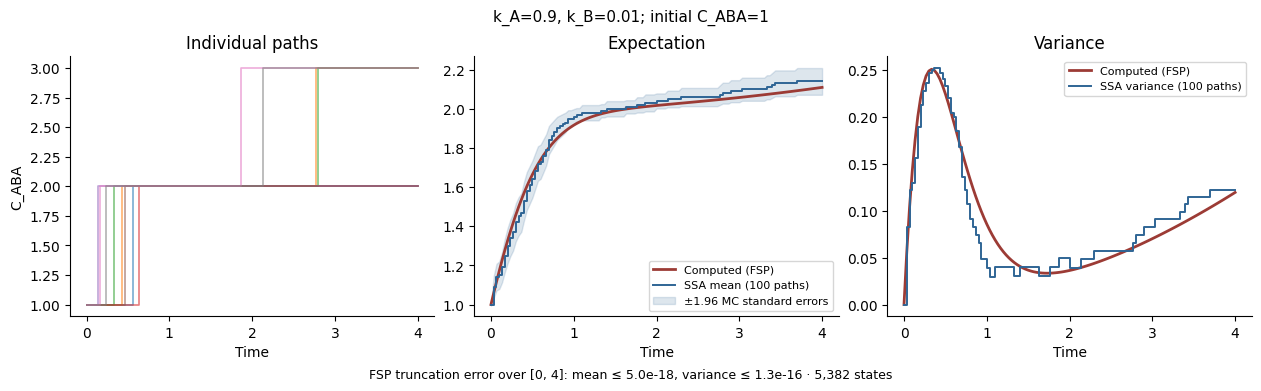

Run All in JupyterLab to activate the sliders.

In [7]:
visual.close_controls(globals().get("controls"))
curves = visual.show_curve(
    visual.aba_curve(result, initial, rates, end=T, paths=RUNS)
)
controls = visual.aba_sliders(result, initial, rates, curves)

[← All examples](../paper_examples.ipynb)